# 📘 ML Fundamentals — Explained Like You're 10
- 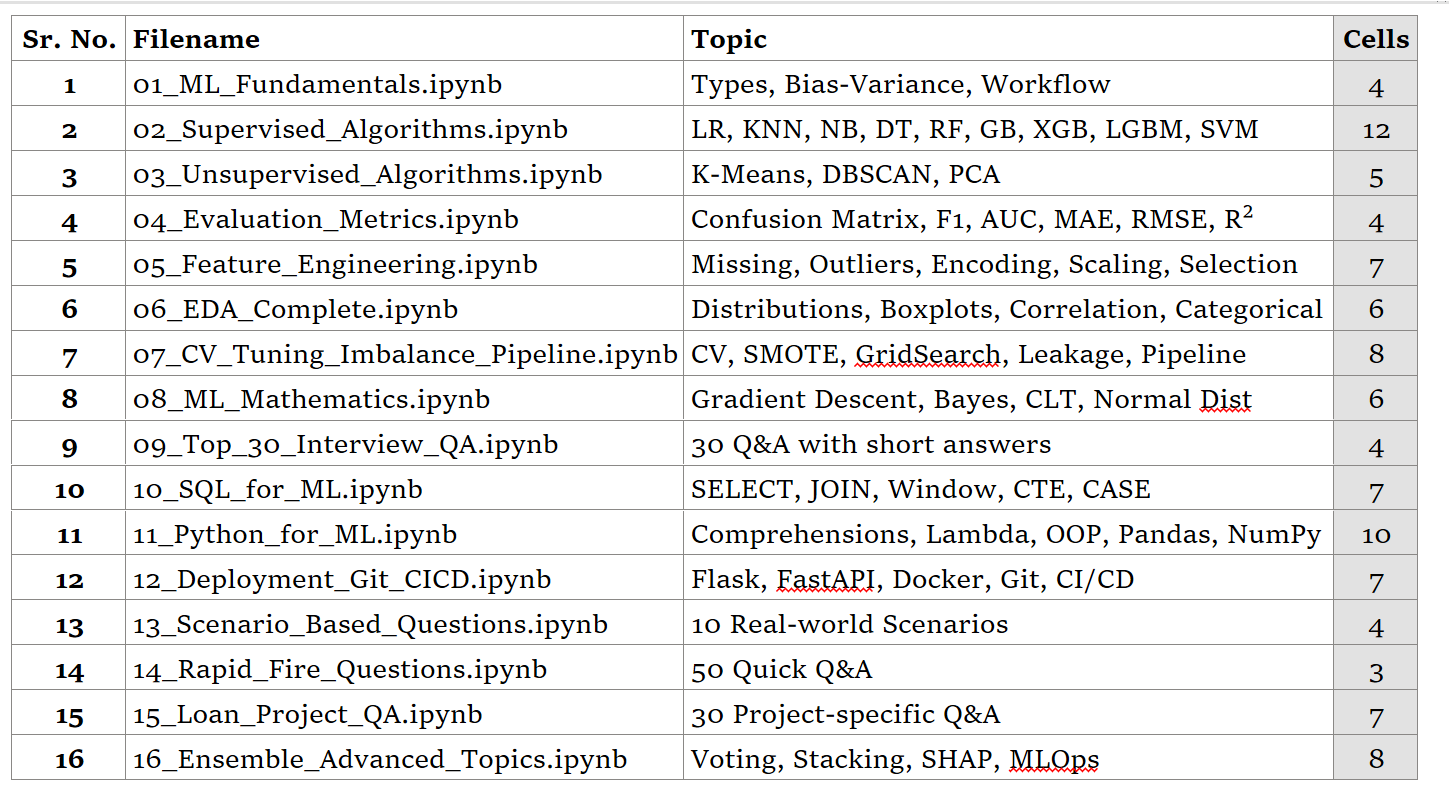
---
## What is Machine Learning?

**ML = Computer learns from data instead of being explicitly programmed.**

---
## Types of ML
```
Machine Learning
├── Supervised (Teacher gives answers)
│   ├── Classification → Categories (Yes/No)
│   └── Regression → Numbers (Price)
├── Unsupervised (No teacher, find patterns)
│   ├── Clustering → Group similar items
│   └── Dimensionality Reduction → Simplify
├── Semi-Supervised (Some answers given)
└── Reinforcement (Rewards & Punishments)
```

---
## Key Terms
| Term | Simple Meaning | Example |
|------|---------------|--------|
| Feature (X) | Input | Age, Salary |
| Target (y) | Answer to predict | Default? |
| Training Data | Data to learn from | 80% |
| Testing Data | Data to test on | 20% |
| Overfitting | Memorizing not learning | Memorizing answers |
| Underfitting | Not learning enough | Not studying |
| Bias | Too simple model | Straight line on curve |
| Variance | Too complex model | Connecting every dot |
| Hyperparameter | WE set before training | Learning rate |
| Parameter | MODEL learns | Weights |

---
## Bias-Variance Tradeoff
- Simple model → High Bias, Low Variance (Underfit)
- Complex model → Low Bias, High Variance (Overfit)

---
## ML Workflow
```
1. Define Problem → 2. Collect Data → 3. EDA → 4. Clean Data
→ 5. Feature Engineering → 6. Split Data → 7. Choose Model
→ 8. Train → 9. Evaluate → 10. Tune → 11. Deploy → 12. Monitor
```

# 1. Install dependencies
```bash
pip install pandas numpy matplotlib seaborn scikit-learn xgboost lightgbm imbalanced-learn jupyter ipykernel scipy
```

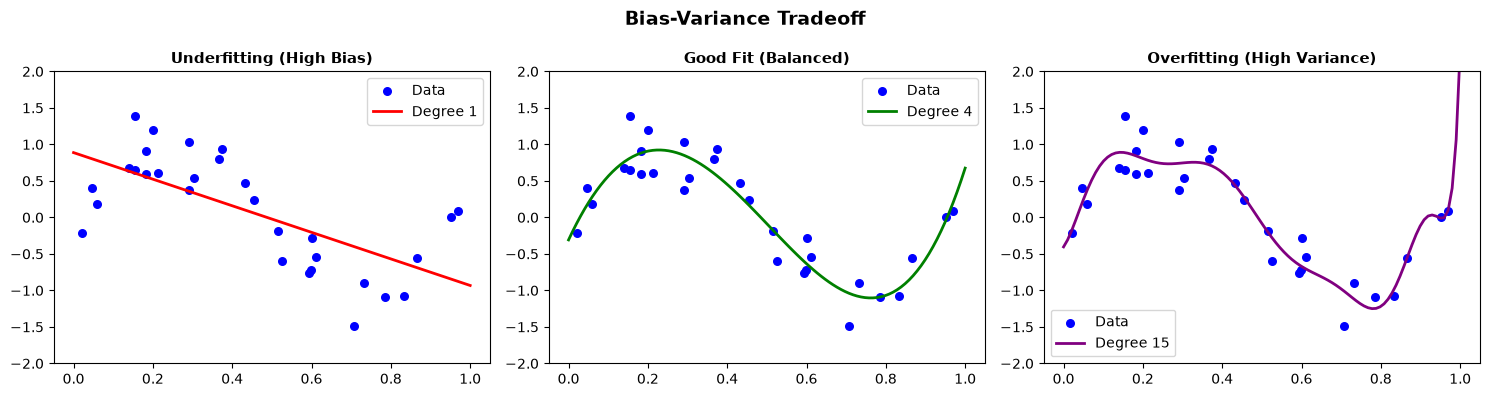

✅ Red = Too simple (misses pattern)
✅ Green = Just right (captures pattern)
✅ Purple = Too complex (memorizes noise)


In [2]:
# ============================================================================
# DEMO: Bias-Variance Tradeoff Visualization
# ============================================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

np.random.seed(42)
X = np.sort(np.random.rand(30))[:, None]
y = np.sin(2 * np.pi * X).ravel() + np.random.randn(30) * 0.3
X_plot = np.linspace(0, 1, 100)[:, None]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
degrees = [1, 4, 15]  # Underfit, Good, Overfit
titles = ['Underfitting (High Bias)', 'Good Fit (Balanced)', 'Overfitting (High Variance)']
colors = ['red', 'green', 'purple']

for ax, deg, title, color in zip(axes, degrees, titles, colors):
    model = Pipeline([('poly', PolynomialFeatures(deg)), ('lr', LinearRegression())])
    model.fit(X, y)
    ax.scatter(X, y, color='blue', s=30, label='Data')
    ax.plot(X_plot, model.predict(X_plot), color=color, linewidth=2, label=f'Degree {deg}')
    ax.set_title(title, fontweight='bold', fontsize=11)
    ax.set_ylim(-2, 2)
    ax.legend()

plt.suptitle('Bias-Variance Tradeoff', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
print('✅ Red = Too simple (misses pattern)')
print('✅ Green = Just right (captures pattern)')
print('✅ Purple = Too complex (memorizes noise)')

C:\Users\rahul\AppData\Local\Temp\ipykernel_17944\198889695.py:26: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\rahul\AppData\Local\Temp\ipykernel_17944\198889695.py:26: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
h:\0-- VSCODE_PROJECTS_TASK\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
h:\0-- VSCODE_PROJECTS_TASK\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


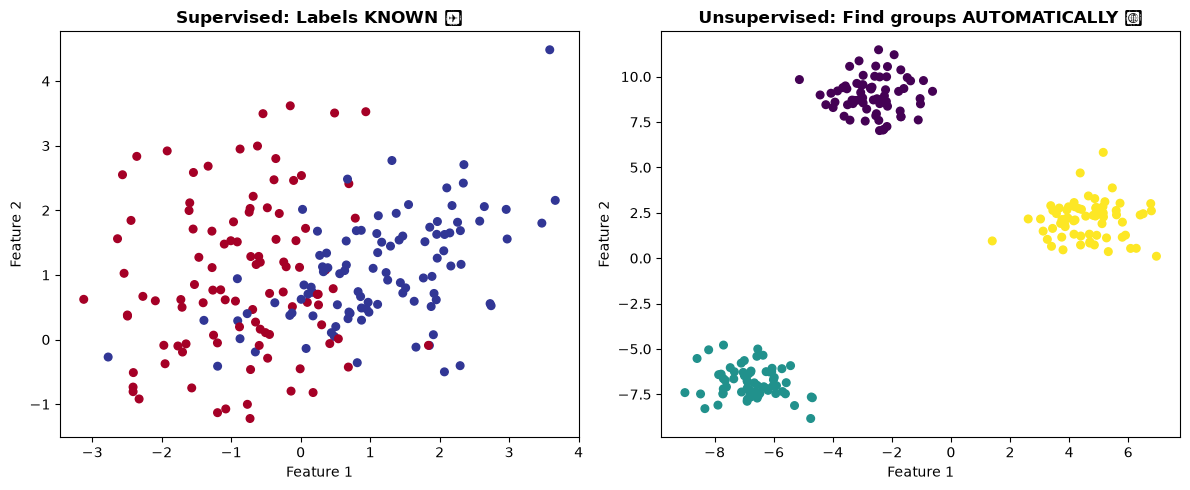

In [3]:
# ============================================================================
# DEMO: Supervised vs Unsupervised
# ============================================================================
from sklearn.datasets import make_classification, make_blobs
from sklearn.cluster import KMeans

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Supervised: We HAVE labels
X_sup, y_sup = make_classification(n_samples=200, n_features=2, n_redundant=0,
                                    n_clusters_per_class=1, random_state=42)
ax1.scatter(X_sup[:, 0], X_sup[:, 1], c=y_sup, cmap='RdYlBu', s=30)
ax1.set_title('Supervised: Labels KNOWN ✅', fontweight='bold')
ax1.set_xlabel('Feature 1')
ax1.set_ylabel('Feature 2')

# Unsupervised: NO labels, find groups
X_unsup, _ = make_blobs(n_samples=200, centers=3, random_state=42)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_unsup)
ax2.scatter(X_unsup[:, 0], X_unsup[:, 1], c=clusters, cmap='viridis', s=30)
ax2.set_title('Unsupervised: Find groups AUTOMATICALLY 🔍', fontweight='bold')
ax2.set_xlabel('Feature 1')
ax2.set_ylabel('Feature 2')

plt.tight_layout()
plt.show()

C:\Users\rahul\AppData\Local\Temp\ipykernel_17944\1937620224.py:24: UserWarning: Glyph 128054 (\N{DOG FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\rahul\AppData\Local\Temp\ipykernel_17944\1937620224.py:24: UserWarning: Glyph 128176 (\N{MONEY BAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
h:\0-- VSCODE_PROJECTS_TASK\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128054 (\N{DOG FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
h:\0-- VSCODE_PROJECTS_TASK\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128176 (\N{MONEY BAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


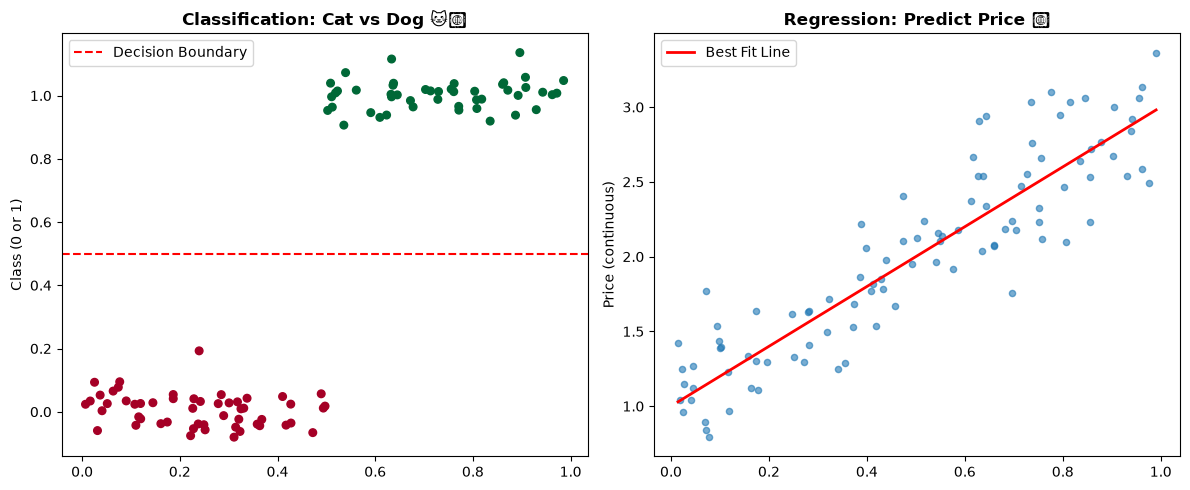

In [4]:
# ============================================================================
# DEMO: Classification vs Regression
# ============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Classification: Predict CATEGORY
X_c = np.random.rand(100)
y_c = (X_c > 0.5).astype(int)
ax1.scatter(X_c, y_c + np.random.randn(100)*0.05, c=y_c, cmap='RdYlGn', s=30)
ax1.axhline(0.5, color='red', linestyle='--', label='Decision Boundary')
ax1.set_title('Classification: Cat vs Dog 🐱🐶', fontweight='bold')
ax1.set_ylabel('Class (0 or 1)')
ax1.legend()

# Regression: Predict NUMBER
X_r = np.sort(np.random.rand(100))
y_r = 2 * X_r + 1 + np.random.randn(100) * 0.3
ax2.scatter(X_r, y_r, s=20, alpha=0.6)
ax2.plot(X_r, 2*X_r + 1, 'r-', linewidth=2, label='Best Fit Line')
ax2.set_title('Regression: Predict Price 💰', fontweight='bold')
ax2.set_ylabel('Price (continuous)')
ax2.legend()

plt.tight_layout()
plt.show()

## 🎯 Key Takeaways
1. ML = Learning from data, not explicit programming
2. Supervised has labels, Unsupervised doesn't
3. Classification = categories, Regression = numbers
4. Balance bias and variance for best results
5. Always follow the ML workflow!